# Restaurant Sales & Tipping Analysis
**Author:** Manish  
**Tools:** Python, Pandas, Matplotlib, Seaborn  
**Objective:** Analyze restaurant billing data to understand revenue patterns and customer tipping behavior.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
df.shape

(244, 7)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [6]:
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 1. Data Cleaning & Preparation

In [7]:
df.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df["tip_pct"] = (df["tip"] / df["total_bill"] * 100).round(2)

In [10]:
df.head()

,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.94
1,10.34,1.66,Male,No,Sun,Dinner,3,16.05
2,21.01,3.50,Male,No,Sun,Dinner,3,16.66
3,23.68,3.31,Male,No,Sun,Dinner,2,13.98
4,24.59,3.61,Female,No,Sun,Dinner,4,14.68


In [11]:
df["tip_pct"].describe()

count    244.000000
mean      16.079754
std        6.107020
min        3.560000
25%       12.910000
50%       15.475000
75%       19.147500
max       71.030000
Name: tip_pct, dtype: float64

## 2. Exploratory Data Analysis

In [12]:
df[df["tip_pct"] > 40]

,total_bill,tip,sex,smoker,day,time,size,tip_pct
172,7.25,5.15,Male,Yes,Sun,Dinner,2,71.03
178,9.60,4.00,Female,Yes,Sun,Dinner,2,41.67


## Question 1: Which day brings in the most revenue?

In [13]:
df.groupby("day")["total_bill"].sum().sort_values(ascending=False)

day
Sat     1778.40
Sun     1627.16
Thur    1096.33
Fri      325.88
Name: total_bill, dtype: float64

## Question 2: Lunch vs dinner

In [14]:
df.groupby("time")["total_bill"].agg(["sum", "mean", "count"])

,sum,mean,count
time,,,
Dinner,3660.30,20.797159,176
Lunch,1167.47,17.168676,68


## Question 3: Does party size change the tip percentage?

In [15]:
df.groupby("size")["tip_pct"].mean().round(2)

size
1    21.73
2    16.57
3    15.21
4    14.59
5    14.15
6    15.62
Name: tip_pct, dtype: float64

## Question 4: Smokers vs non-smokers

In [16]:
df.groupby("smoker")["tip_pct"].mean().round(2)

smoker
No     15.93
Yes    16.32
Name: tip_pct, dtype: float64

## 3. Data Visualization

In [17]:
df["day"].value_counts()

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

In [18]:
df["size"].value_counts().sort_index()

size
1      4
2    156
3     38
4     37
5      5
6      4
Name: count, dtype: int64

In [19]:
sns.set_theme(style="whitegrid")

## Chart 1: Total revenue by day

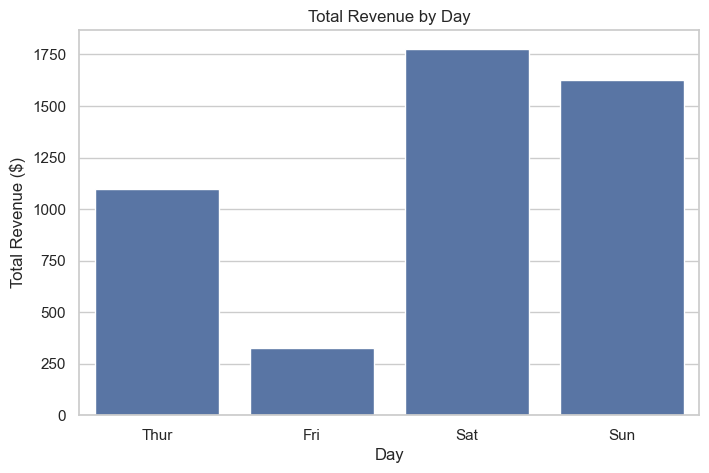

In [20]:
day_order = ["Thur", "Fri", "Sat", "Sun"]

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="day", y="total_bill", order=day_order,
            estimator="sum", errorbar=None, color="#4C72B0")
plt.title("Total Revenue by Day")
plt.xlabel("Day")
plt.ylabel("Total Revenue ($)")
plt.show()

## Chart 2: Average tip percentage by party size

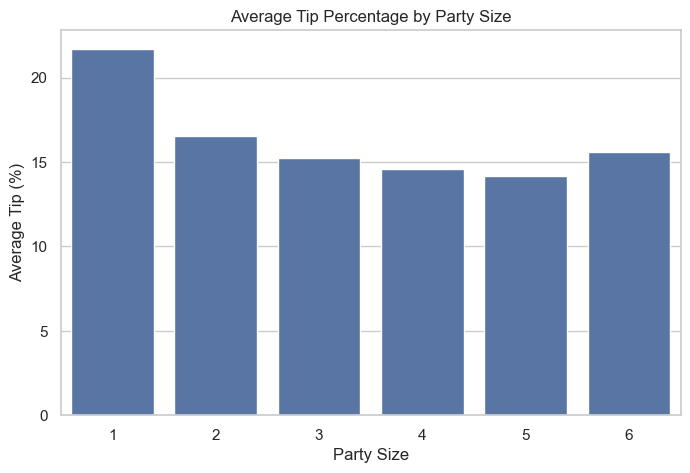

In [21]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="size", y="tip_pct", errorbar=None, color="#4C72B0")
plt.title("Average Tip Percentage by Party Size")
plt.xlabel("Party Size")
plt.ylabel("Average Tip (%)")
plt.show()

## Chart 3: Bill vs tip

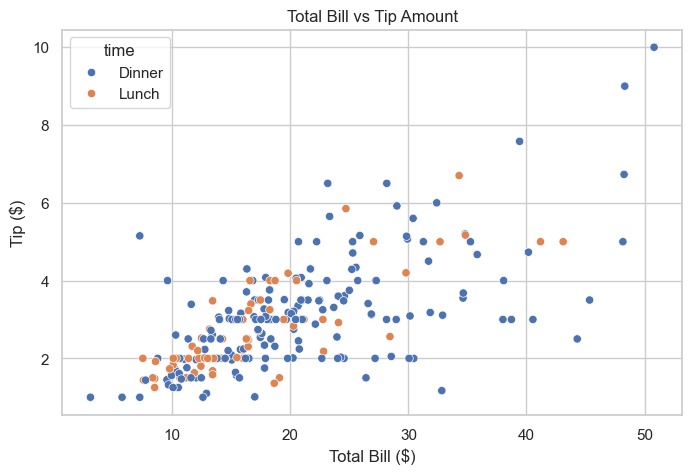

In [22]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="total_bill", y="tip", hue="time")
plt.title("Total Bill vs Tip Amount")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.show()

## Chart 4: Distribution of tip percentage

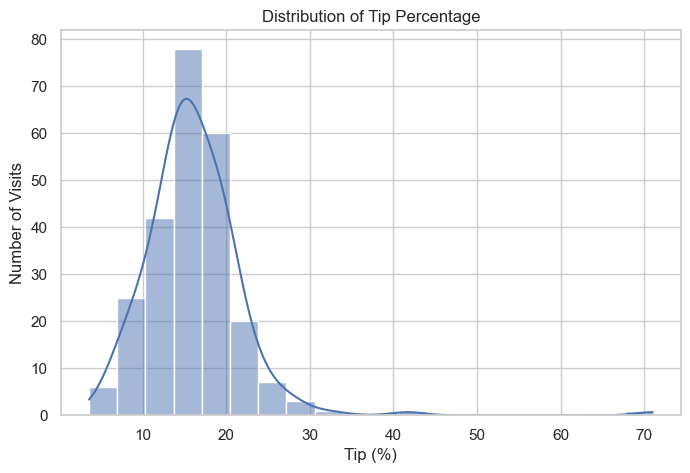

In [23]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="tip_pct", bins=20, kde=True, color="#4C72B0")
plt.title("Distribution of Tip Percentage")
plt.xlabel("Tip (%)")
plt.ylabel("Number of Visits")
plt.show()

In [24]:
import os
os.makedirs("images", exist_ok=True)

In [25]:
plt.savefig("images/01_revenue_by_day.png", dpi=150, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [26]:
plt.savefig("images/02_tip_pct_by_party_size.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [27]:
plt.savefig("images/03_bill_vs_tip.png", dpi=150, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [29]:
plt.savefig("images/04_tip_pct_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

## 4. Key Findings

1. **Weekends drive revenue.** Saturday and Sunday together account for about 70% of total revenue in this dataset.
2. **Dinner is the main revenue source.** Dinner generates about 76% of revenue and has a higher average bill ($20.80) than lunch ($17.17).
3. **Tipping is steady around 16%.** The average tip is 16.1% of the bill (median 15.5%), with a small number of unusually high tips, such as one at 71%.
4. **Larger groups tip a slightly lower percentage.** Parties of 2 to 5 show a gradual decline from 16.6% to 14.2%.
5. **Smoking status has almost no effect on tipping.** Smokers tip 16.3% on average and non-smokers 15.9%, a negligible difference.

## 5. Limitations
- The dataset has only 244 records, so results show patterns in this sample, not definitive facts.
- Friday has only 19 visits, so its low total revenue mostly reflects fewer recorded visits.
- Party sizes 1, 5 and 6 each have fewer than 6 visits, so their tip percentages are not reliable.
- The data does not include dates or restaurant location, so trends over time cannot be analyzed.

## 6. Recommendations
- Focus staffing and promotions on weekend dinners, the busiest and highest-value period.
- Investigate why Friday has so few visits (marketing, opening hours, or data coverage).